# Rekurzivní algoritmy a dynamické programování

**PDSA · Téma 6**  
Jaroslav Radimsky

## Fibonacciho čísla

Pro nezáporné celé číslo `n` počítáme `F(n)`. Všechny čtyři varianty používají základní hodnoty `F(0) = 0` a `F(1) = 1`.

### Přímá rekurze

Stav je index `n`. Pro 0 a 1 vrátíme přímo `n`. Jinak rekurzivně získáme `F(n−1)` a `F(n−2)` a jako výsledek vrátíme jejich součet. Opakované požadavky na stejný stav počítáme znovu.

In [1]:
def fib_recursive(n, *, ops=None):
    if n <= 1:
        return n

    left = fib_recursive(n - 1, ops=ops)
    right = fib_recursive(n - 2, ops=ops)
    if ops is not None:
        ops[0] += 1
    return left + right

### Rekurze s memoizací

Stav `memo[k]` uchovává `F(k)`. Každé volání `fib_memo` vytvoří nový slovník s hodnotami pro 0 a 1. Vnitřní funkce vrátí uloženou hodnotu, pokud existuje. Jinak uloží součet výsledků pro `k−1` a `k−2`. Výsledkem je hodnota stavu `n`.

In [2]:
def fib_memo(n, *, ops=None):
    memo = {0: 0, 1: 1}

    def solve(k):
        if k not in memo:
            memo[k] = solve(k - 1) + solve(k - 2)
            if ops is not None:
                ops[0] += 1
        return memo[k]

    return solve(n)

### Pomocné funkce pro kontrolní tabulky a podposloupnosti

In [3]:
from html import escape

from IPython.display import HTML, display


def show_table(headers, rows):
    def row_html(values, tag):
        items = (f"<{tag}>{escape(str(v))}</{tag}>" for v in values)
        return "<tr>" + "".join(items) + "</tr>"

    head = row_html(headers, "th")
    body = "".join(row_html(row, "td") for row in rows)
    display(HTML(f"<table><thead>{head}</thead><tbody>{body}</tbody></table>"))


def is_subsequence(sequence, source):
    remaining = iter(source)
    return all(value in remaining for value in sequence)

### Tabulace

Stav `dp[k]` uchovává `F(k)`. Pro 0 a 1 vrátíme přímo `n`. Jinak nastavíme první dvě buňky na 0 a 1. Ve vzestupném pořadí dosazujeme součet předchozích dvou buněk a vrátíme `dp[n]`.

In [4]:
def fib_tab(n, *, ops=None):
    if n <= 1:
        return n

    dp = [0] * (n + 1)
    dp[1] = 1
    for k in range(2, n + 1):
        dp[k] = dp[k - 1] + dp[k - 2]
        if ops is not None:
            ops[0] += 1
    return dp[n]

### Úsporná iterace

Před krokem `k` stav tvoří dvojice `F(k−2), F(k−1)`. Pro 0 a 1 vrátíme přímo `n`. Výpočet odstartuje dvojice `(0, 1)`. V každém kroku posuneme dvojici o jednu pozici, přičemž druhou hodnotou se stane součet. Po kroku `n` vrátíme druhou hodnotu.

In [5]:
def fib_iter(n, *, ops=None):
    if n <= 1:
        return n

    previous, current = 0, 1
    for k in range(2, n + 1):
        previous, current = current, previous + current
        if ops is not None:
            ops[0] += 1
    return current

### Kontroly Fibonacciho čísel

In [6]:
fib_methods = {
    "Přímá rekurze": fib_recursive,
    "Memoizace": fib_memo,
    "Tabulace": fib_tab,
    "Úsporná iterace": fib_iter,
}

rows = []
for n, expected in [(0, 0), (1, 1), (2, 1), (6, 8), (10, 55)]:
    results = [function(n) for function in fib_methods.values()]
    assert all(value == expected for value in results)
    rows.append((n, expected, *results))

show_table(("n", "Očekáváno", *fib_methods), rows)

n,Očekáváno,Přímá rekurze,Memoizace,Tabulace,Úsporná iterace
0,0,0,0,0,0
1,1,1,1,1,1
2,1,1,1,1,1
6,8,8,8,8,8
10,55,55,55,55,55


## Nejdelší rostoucí podposloupnost (LIS)

Stav `dp[i]` je největší délka striktně rostoucí podposloupnosti končící na indexu `i`. Na každé pozici je výchozí délkou 1 a předchůdce chybí. Prázdný vstup má délku 0. Zleva doprava zkoušíme každé `j < i`. Pokud `a[j] < a[i]` a délka `dp[j] + 1` zlepší stav, zapíšeme ji a uložíme `j` do pole předchůdců. Každé řešení končící na `i` má buď jeden prvek, nebo některého z těchto předchůdců. Od indexu maxima v `dp` projdeme předchůdce a obrátíme pořadí získaných prvků.

In [7]:
def lis(a, *, ops=None):
    n = len(a)
    if n == 0:
        return 0, []

    dp = [1] * n
    pred = [-1] * n
    for i in range(n):
        for j in range(i):
            if ops is not None:
                ops[0] += 1
            if a[j] < a[i] and dp[j] + 1 > dp[i]:
                dp[i] = dp[j] + 1
                pred[i] = j

    i = max(range(n), key=dp.__getitem__)
    length = dp[i]
    sequence = []
    while i != -1:
        sequence.append(a[i])
        i = pred[i]
    sequence.reverse()
    return length, sequence

### Kontroly LIS

Vlastní případ `[-3, -1, -2, 0, -5]` ověřuje záporné hodnoty a maximum před poslední pozicí.

In [8]:
def check_lis(a, result, expected_length=None):
    length, sequence = result
    if expected_length is not None:
        assert length == expected_length
    assert len(sequence) == length
    assert all(x < y for x, y in zip(sequence, sequence[1:]))
    assert is_subsequence(sequence, a)


rows = []
for a, expected in [
    ([], 0), ([7], 1), ([1, 2, 3, 4], 4),
    ([4, 3, 2, 1], 1), ([2, 2, 2], 1), ([3, 1, 2, 5, 4, 6], 4),
    ([-3, -1, -2, 0, -5], 3),
]:
    result = lis(a)
    check_lis(a, result, expected)
    rows.append((a, expected, *result))

show_table(("Vstup", "Očekávaná délka", "Délka", "Podposloupnost"), rows)

Vstup,Očekávaná délka,Délka,Podposloupnost
[],0,0,[]
[7],1,1,[7]
"[1, 2, 3, 4]",4,4,"[1, 2, 3, 4]"
"[4, 3, 2, 1]",1,1,[4]
"[2, 2, 2]",1,1,[2]
"[3, 1, 2, 5, 4, 6]",4,4,"[1, 2, 5, 6]"
"[-3, -1, -2, 0, -5]",3,3,"[-3, -1, 0]"


## Nejdelší společná podposloupnost (LCS)

Stav `dp[i][j]` je délka LCS prefixů `x[:i]` a `y[:j]`. Pokud je jeden prefix prázdný, délka je 0. Tabulku plníme po řádcích. Při shodě posledních znaků vezmeme diagonální hodnotu a přičteme 1. Při neshodě alespoň jeden z posledních znaků vynecháme a vezmeme maximum z hodnoty nahoře a vlevo. Délku čteme v pravém dolním rohu. Při zpětném průchodu ukládáme shodné znaky při pohybu po diagonále, jinak sledujeme většího souseda a při remíze jdeme nahoru. Znaky nakonec obrátíme a spojíme do řetězce.

In [9]:
def lcs(x, y, *, ops=None):
    m, n = len(x), len(y)
    if m == 0 or n == 0:
        return 0, ""

    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if x[i - 1] == y[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])
            if ops is not None:
                ops[0] += 1

    i, j = m, n
    sequence = []
    while i > 0 and j > 0:
        if x[i - 1] == y[j - 1]:
            sequence.append(x[i - 1])
            i, j = i - 1, j - 1
        elif dp[i - 1][j] >= dp[i][j - 1]:
            i -= 1
        else:
            j -= 1
    return dp[m][n], "".join(reversed(sequence))

### Kontroly LCS

Vlastní případ `"ABAB", "BABA"` ověřuje opakující se znaky a připouští více optimálních výsledků.

In [10]:
def check_lcs(x, y, result, expected_length=None):
    length, sequence = result
    if expected_length is not None:
        assert length == expected_length
    assert len(sequence) == length
    assert is_subsequence(sequence, x)
    assert is_subsequence(sequence, y)


rows = []
for x, y, expected in [
    ("", "ABC", 0), ("ABC", "ABC", 3), ("ABC", "DEF", 0),
    ("ABC", "BAC", 2), ("ABAB", "BABA", 3),
]:
    result = lcs(x, y)
    check_lcs(x, y, result, expected)
    length, sequence = result
    rows.append((repr(x), repr(y), expected, length, repr(sequence)))

show_table(("X", "Y", "Očekávaná délka", "Délka", "Podposloupnost"), rows)

X,Y,Očekávaná délka,Délka,Podposloupnost
'','ABC',0,0,''
'ABC','ABC',3,3,'ABC'
'ABC','DEF',0,0,''
'ABC','BAC',2,2,'AC'
'ABAB','BABA',3,3,'ABA'


## Experimenty

Vstupy připravuji před měřením s generátorem se seedem 42. Každý případ má jeden zahřívací a pět měřených běhů. Uvádím medián v milisekundách z `perf_counter()`. Generování vstupů, ověřování výsledků a vykreslování probíhá mimo měřený úsek. Čítač `ops` zapínám pouze v samostatném běhu pro počet operací. Memoizace vždy začíná s novým slovníkem obsahujícím jen základní případy.

In [11]:
from random import Random
from statistics import median
from time import perf_counter

import matplotlib.pyplot as plt


def measure(function, *args):
    expected = function(*args)
    durations = []
    for _ in range(5):
        start = perf_counter()
        result = function(*args)
        elapsed = perf_counter() - start
        assert result == expected
        durations.append(elapsed)

    ops = [0]
    counted_result = function(*args, ops=ops)
    assert counted_result == expected
    return expected, median(durations) * 1000, ops[0]

In [12]:
def plot_results(sizes, size_label, times, counts, count_label,
                 log_y=False):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), layout="constrained")
    panels = (
        (times, "Medián času [ms]"),
        (counts, count_label),
    )
    styles = ("o-", "s--", "^:", "d-.")
    for ax, (series, ylabel) in zip(axes, panels):
        for (label, values), style in zip(series.items(), styles):
            ax.plot(sizes, values, style, label=label, markersize=4)
        ax.set(xlabel=size_label, ylabel=ylabel, xticks=sizes)
        if log_y:
            ax.set_yscale("log")
        ax.grid(axis="y", alpha=0.25)
        ax.legend(fontsize=8)

    plt.show()
    plt.close(fig)

### Fibonacciho čísla

Pro každou velikost ověřuji shodu všech čtyř výsledků. Součet počítám jednou pro každé skutečné vyhodnocení `F(k−1) + F(k−2)`. Svislá osa obou grafů je logaritmická. Tři úspornější varianty mají totožné počty součtů.

In [13]:
fib_sizes = (5, 10, 15, 20, 25)
fib_times = {label: [] for label in fib_methods}
fib_counts = {"Přímá rekurze": [], "Zbývající tři varianty": []}
rows = []
for n in fib_sizes:
    reference = fib_iter(n)
    counts_at_n = {}
    for label, function in fib_methods.items():
        result, time_ms, count = measure(function, n)
        assert result == reference
        fib_times[label].append(time_ms)
        assert count == (fib_iter(n + 1) - 1 if label == "Přímá rekurze"
                         else n - 1)
        counts_at_n[label] = count
        rows.append((n, label, result, f"{time_ms:.6f}", count))
    fib_counts["Přímá rekurze"].append(counts_at_n["Přímá rekurze"])
    fib_counts["Zbývající tři varianty"].append(counts_at_n["Memoizace"])

### Výsledky měření Fibonacciho čísel

n,Varianta,F(n),Medián [ms],Součty
5,Přímá rekurze,5,0.001300,7
5,Memoizace,5,0.001300,4
5,Tabulace,5,0.000500,4
5,Úsporná iterace,5,0.000400,4
10,Přímá rekurze,55,0.010300,88
10,Memoizace,55,0.002200,9
10,Tabulace,55,0.000800,9
10,Úsporná iterace,55,0.000400,9
15,Přímá rekurze,610,0.127600,986
15,Memoizace,610,0.003600,14


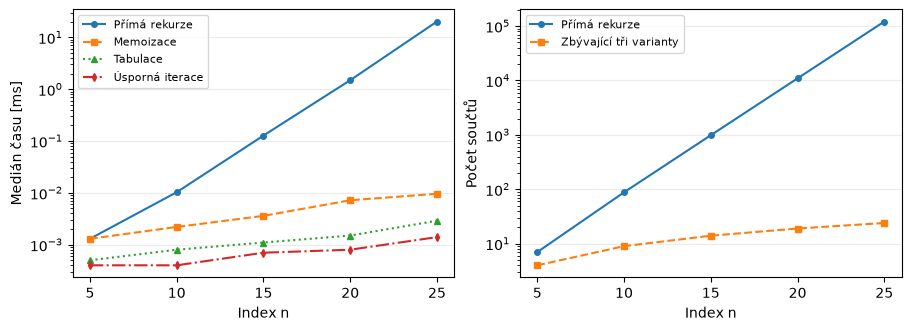

In [14]:
show_table(("n", "Varianta", "F(n)", "Medián [ms]", "Součty"), rows)
plot_results(
    fib_sizes, "Index n", fib_times, fib_counts, "Počet součtů", log_y=True
)

### LIS na náhodném a seřazeném vstupu

Pro každé `n` generuji jeden seznam z intervalu `[0, 999]` a z něj vytvořím obě seřazené kopie. U všech běhů kontroluji platnost vrácené podposloupnosti a počet prověřených dvojic.

n,Uspořádání,Délka LIS,Medián [ms],Dvojice
100,Náhodné,16,0.266200,4950
100,Vzestupné,93,0.426800,4950
100,Sestupné,1,0.149700,4950
300,Náhodné,27,1.853200,44850
300,Vzestupné,257,3.678800,44850
300,Sestupné,1,1.185300,44850
600,Náhodné,46,8.388500,179700
600,Vzestupné,468,14.102800,179700
600,Sestupné,1,4.909500,179700
1000,Náhodné,59,24.009100,499500


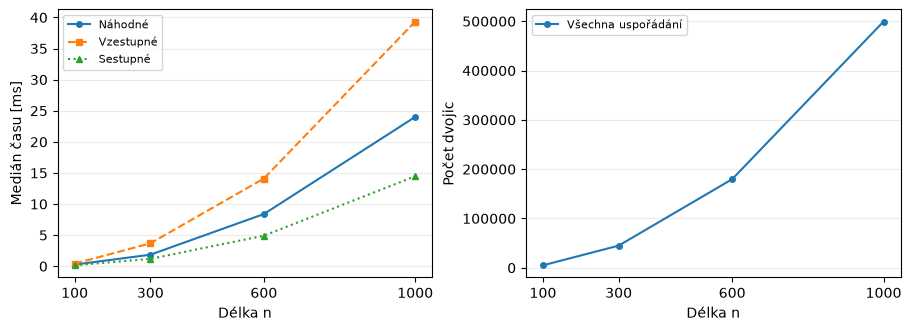

In [15]:
rng = Random(42)
lis_sizes = (100, 300, 600, 1000)
orders = ("Náhodné", "Vzestupné", "Sestupné")
lis_times = {order: [] for order in orders}
lis_counts = {"Všechna uspořádání": []}
rows = []

for n in lis_sizes:
    a = [rng.randint(0, 999) for _ in range(n)]
    inputs = (a, sorted(a), sorted(a, reverse=True))
    pairs = n * (n - 1) // 2
    lis_counts["Všechna uspořádání"].append(pairs)
    for order, values in zip(orders, inputs):
        result, time_ms, count = measure(lis, values)
        check_lis(values, result)
        assert count == pairs
        lis_times[order].append(time_ms)
        rows.append((n, order, result[0], f"{time_ms:.6f}", count))

show_table(("n", "Uspořádání", "Délka LIS", "Medián [ms]", "Dvojice"),
           rows)
plot_results(lis_sizes, "Délka n", lis_times, lis_counts, "Počet dvojic")

### LCS na dvojicích řetězců

Pro každé `k` generuji dva řetězce délky `k` nezávislým výběrem znaků z abecedy `ABCD`. Počítám pouze vnitřní buňky tabulky, tedy buňky s oběma indexy většími než nula.

k,Délka LCS,Medián [ms],Vnitřní buňky
50,30,0.259400,2500
100,63,1.145400,10000
200,124,4.672300,40000
400,258,17.811800,160000


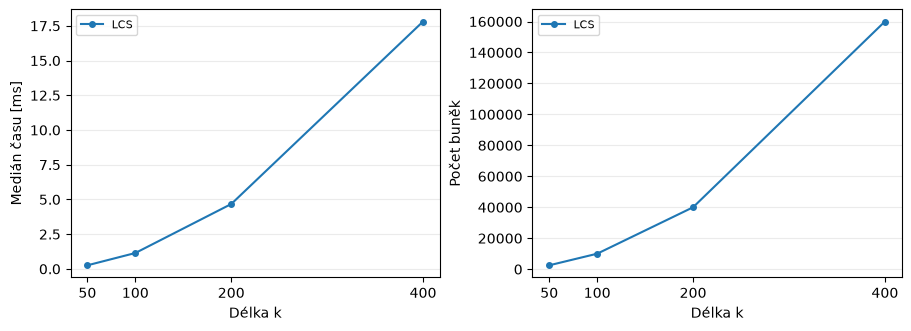

In [16]:
rng = Random(42)
lcs_sizes = (50, 100, 200, 400)
lcs_times = {"LCS": []}
lcs_counts = {"LCS": []}
rows = []

for k in lcs_sizes:
    x = "".join(rng.choices("ABCD", k=k))
    y = "".join(rng.choices("ABCD", k=k))
    result, time_ms, count = measure(lcs, x, y)
    check_lcs(x, y, result)
    assert count == k * k
    lcs_times["LCS"].append(time_ms)
    lcs_counts["LCS"].append(count)
    rows.append((k, result[0], f"{time_ms:.6f}", count))

show_table(("k", "Délka LCS", "Medián [ms]", "Vnitřní buňky"), rows)
plot_results(lcs_sizes, "Délka k", lcs_times, lcs_counts, "Počet buněk")

## Závěr

| Algoritmus | Čas | Pomocná paměť |
|---|---:|---:|
| Fibonacci, přímá rekurze | Θ(φⁿ) | O(n) |
| Fibonacci, memoizace | Θ(n) | O(n) |
| Fibonacci, tabulace | Θ(n) | O(n) |
| Fibonacci, úsporná iterace | Θ(n) | O(1) čísel |
| LIS, tabulace | Θ(n²) | O(n) |
| LCS, tabulace | Θ(mn) | Θ((m+1)(n+1)) |

- **Fibonacci.** Přímá rekurze větví výpočet pro každý stav nad 1 a znovu řeší stejné podúlohy. Počet součtů splňuje `A(n) = A(n−1) + A(n−2) + 1` se dvěma nulovými základními případy. Pro `n = 25` je to 121 392 součtů. Memoizace, tabulace a úsporná iterace potřebují každá 24 součtů, protože každou hodnotu od `F(2)` spočítají jednou.
- **LIS.** Vnitřní smyčka kontroluje všech `n(n−1)/2` dvojic bez ohledu na uspořádání. Při `n = 1000` je to 499 500 dvojic. U sestupné kopie je délka LIS 1, u vzestupné kopie je rovna počtu různých hodnot. Pro `n = 1000` trvala nejdéle vzestupná kopie, u které častěji uspěla podmínka pro zápis do tabulky. U sestupné kopie se stav nikdy nezlepšil.
- **LCS.** Zdvojnásobení obou délek změní počet vnitřních buněk z `mn` na `4mn`. V experimentu počet narostl z 40 000 při `k = 200` na 160 000 při `k = 400`. Zpětný průchod má čas O(m+n). Naměřené časy ovlivňuje i prostředí běhu.

Odhady pro Fibonacciho čísla vyjadřují čas v modelu s konstantní cenou součtu a prostor počtem uložených čísel a rámců zásobníku. V Pythonu roste bitová délka hodnoty `F(n)` s indexem. Odhady pro LIS a LCS platí pro neprázdné vstupy a konstantní cenu porovnání.